IRIS DATASET
--------------------------------------------------
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Dataset Shape: (150, 4)
K = 1  |  Accuracy = 0.9667
K = 3  |  Accuracy = 0.9333
K = 5  |  Accuracy = 0.9333
K = 7  |  Accuracy = 0.9667
K = 9  |  Accuracy = 0.9667

K VALUE COMPARISON
--------------------------------------------------
   K Value  Accuracy
0        1  0.966667
1        3  0.933333
2        5  0.933333
3        7  0.966667
4        9  0.966667

BEST K VALUE
--------------------------------------------------
Best K: 1
Best Accuracy: 0.9667


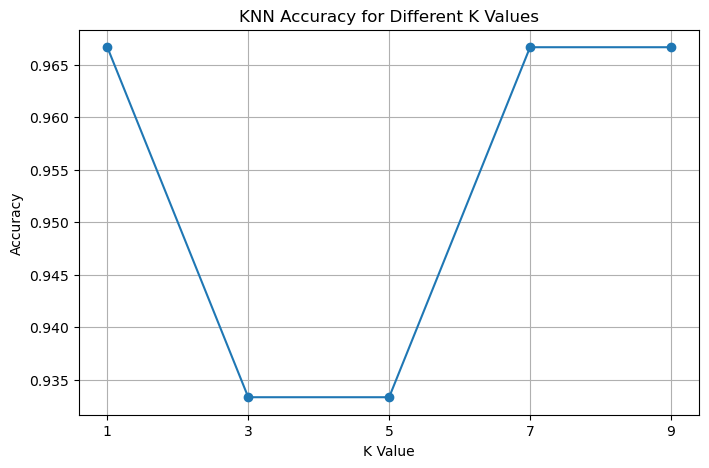


Results saved as: knn_k_comparison.csv


In [3]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score


# ---------------------------------------------------------
# 1. Load Iris Dataset
# ---------------------------------------------------------

data = load_iris()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("IRIS DATASET")
print("-" * 50)
print(X.head())

print("\nDataset Shape:", X.shape)


# ---------------------------------------------------------
# 2. Split the Dataset
# ---------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# ---------------------------------------------------------
# 3. Scale the Features
# ---------------------------------------------------------

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# ---------------------------------------------------------
# 4. Test Different K Values
# ---------------------------------------------------------

k_values = [1, 3, 5, 7, 9]
accuracies = []

for k in k_values:

    model = KNeighborsClassifier(n_neighbors=k)

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    accuracies.append(accuracy)

    print(f"K = {k}  |  Accuracy = {accuracy:.4f}")


# ---------------------------------------------------------
# 5. Create Results Table
# ---------------------------------------------------------

results = pd.DataFrame({
    "K Value": k_values,
    "Accuracy": accuracies
})

print("\nK VALUE COMPARISON")
print("-" * 50)
print(results)


# ---------------------------------------------------------
# 6. Find Best K
# ---------------------------------------------------------

best_index = accuracies.index(max(accuracies))
best_k = k_values[best_index]
best_accuracy = accuracies[best_index]

print("\nBEST K VALUE")
print("-" * 50)
print("Best K:", best_k)
print("Best Accuracy:", round(best_accuracy, 4))


# ---------------------------------------------------------
# 7. Plot K vs Accuracy
# ---------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    accuracies,
    marker="o"
)

plt.title("KNN Accuracy for Different K Values")
plt.xlabel("K Value")
plt.ylabel("Accuracy")
plt.xticks(k_values)
plt.grid(True)

plt.show()


# ---------------------------------------------------------
# 8. Save Results
# ---------------------------------------------------------

results.to_csv(
    "knn_k_comparison.csv",
    index=False
)

print("\nResults saved as: knn_k_comparison.csv")

